In [14]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
import joblib
import os

def visualizar_arboles(proteinas, directory='./liposome_models-np_type', export_dir='./graficos_pdf'):
    """
    Carga los modelos especificados y grafica los primeros 3 árboles de decisión 
    generados para cada proteína, utilizando la estructura de la imagen adjunta.
    """
    
    # Crear la carpeta para los PDFs si no existe
    os.makedirs(export_dir, exist_ok=True)
    
    # 1. Cargar las columnas guardadas (Esto reemplaza al 'X.columns' de la imagen)
    columns_filepath = os.path.join(directory, 'training_columns.joblib')
    try:
        X_columns = joblib.load(columns_filepath)
    except FileNotFoundError:
        print(f"Error: No se encontró el archivo de columnas en {columns_filepath}.")
        print("Asegúrate de haber ejecutado fit_csv previamente.")
        return

    # 2. Iterar sobre las proteínas
    for target in proteinas:
        filepath = os.path.join(directory, f'random_forest_regressor_model_{target}.joblib')
        
        try:
            modelo = joblib.load(filepath)
        except FileNotFoundError:
            print(f"Advertencia: Modelo para {target} no encontrado. Se omite.")
            continue
            
        print(f"\n=======================================================")
        print(f"--- Procesando la proteína {target} ---")
        
        # 3. LÓGICA DE LA IMAGEN: Iterar sobre los primeros 3 estimadores
        for i, estimator in enumerate(modelo.estimators_[:1]):
            plt.figure(figsize=(20, 10))
            
            plot_tree(estimator, 
                      #max_depth=3, 
                      feature_names=X_columns, # Usamos las columnas que cargamos
                      filled=True, 
                      rounded=True, 
                      proportion=False, 
                      precision=2)
            
            plt.title(f'Árbol de Decisión {i+1} - {target}', fontsize=16)

            # --- EXPORTAR A PDF ---
            # El bbox_inches='tight' asegura que no se corten los bordes del gráfico al guardar
            pdf_path = os.path.join(export_dir, f'Arbol_{i+1}_{target}.pdf')
            plt.savefig(pdf_path, format='pdf', bbox_inches='tight')
            print(f"✅ Árbol {i+1} guardado en: {pdf_path}")
            
            plt.show()


--- Procesando la proteína P02768 ---
✅ Árbol 1 guardado en: ./graficos_pdf\Arbol_1_P02768.pdf


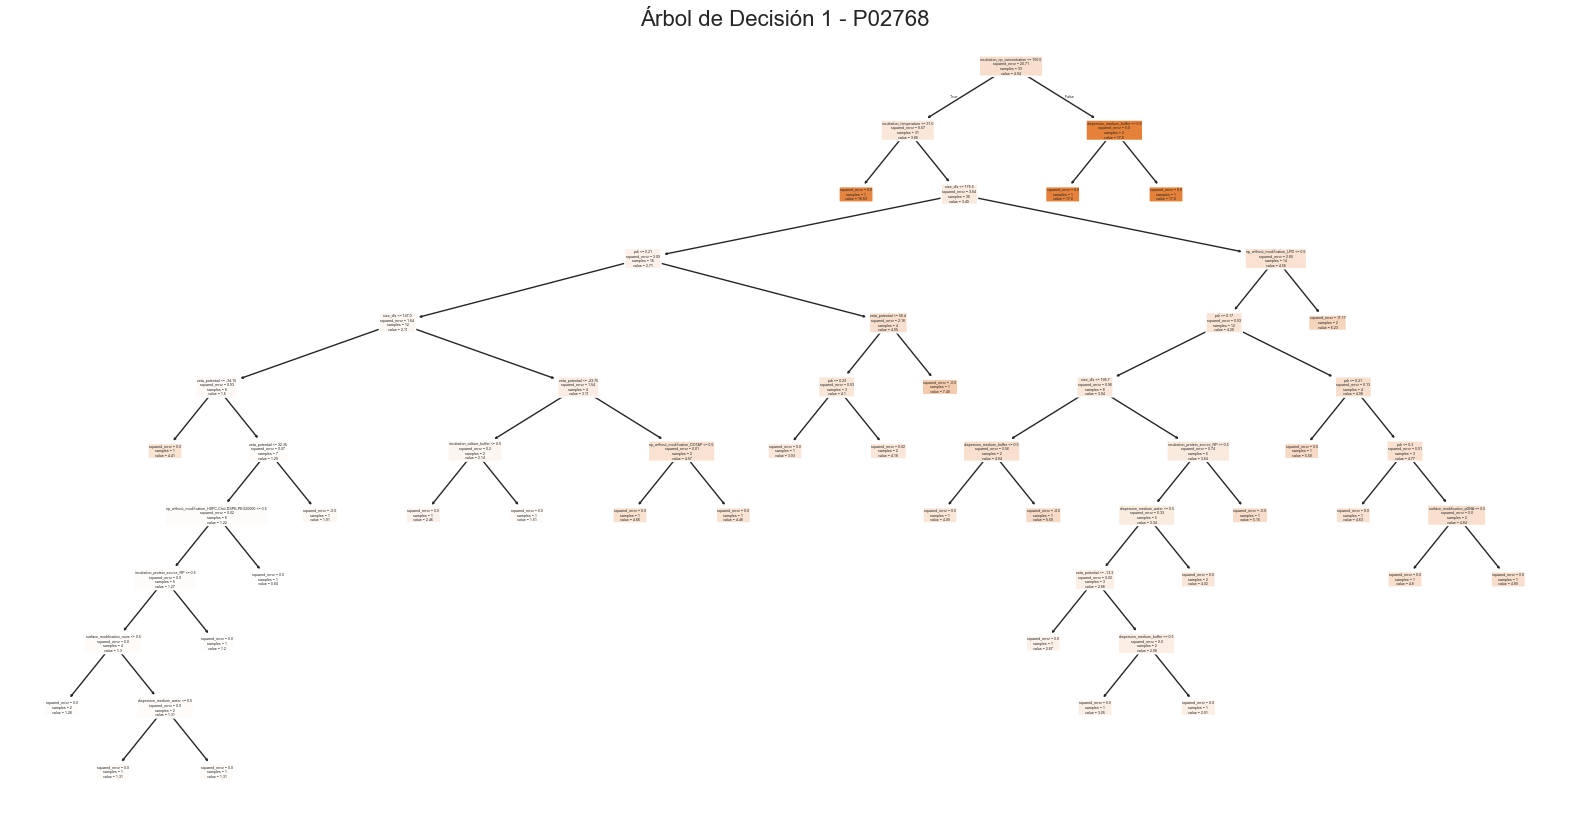


--- Procesando la proteína P01024 ---
✅ Árbol 1 guardado en: ./graficos_pdf\Arbol_1_P01024.pdf


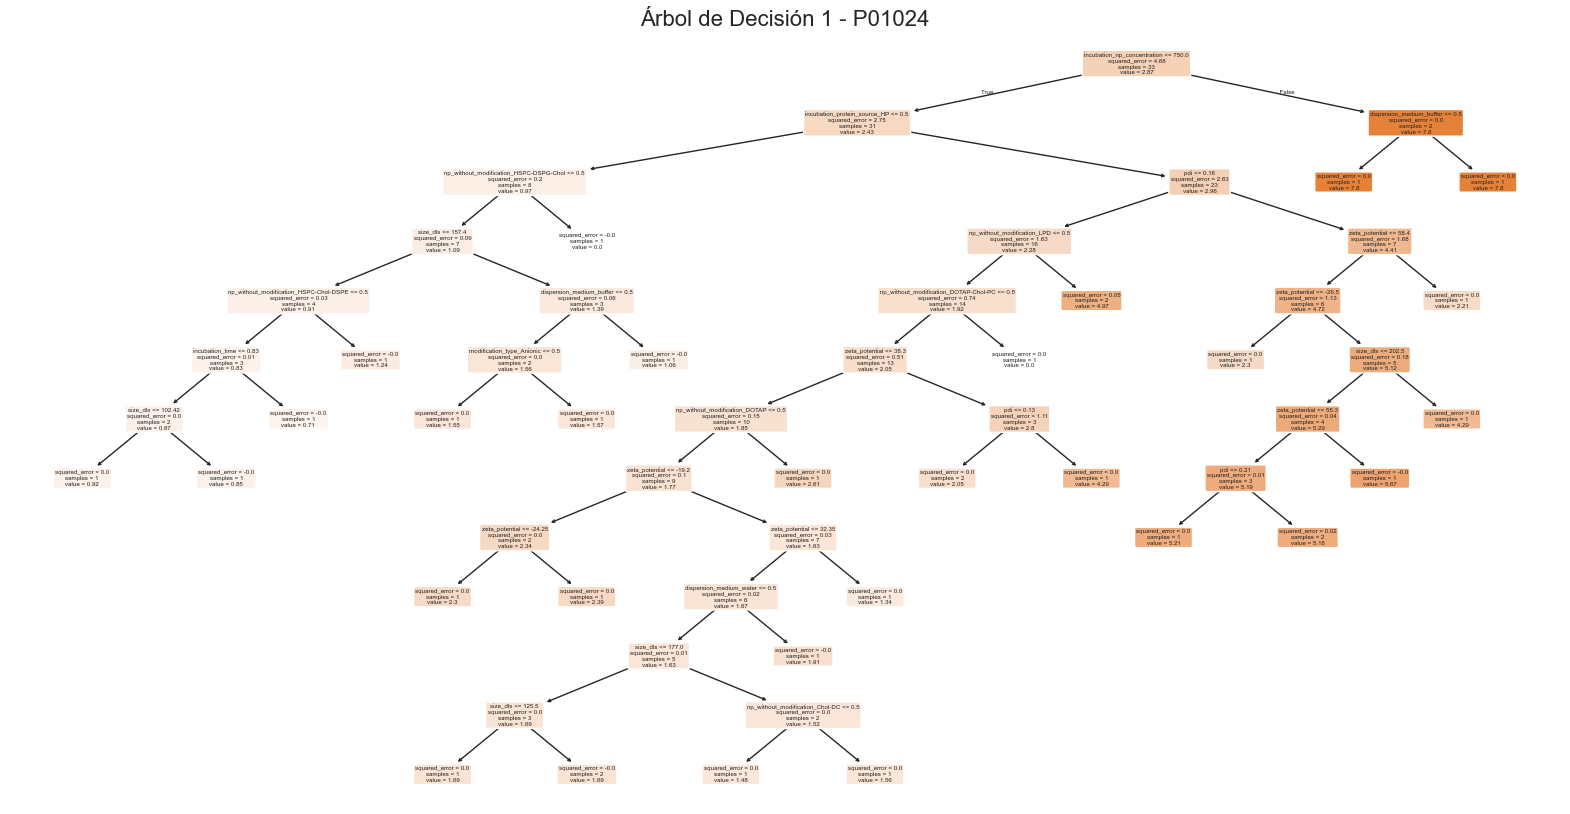


--- Procesando la proteína P0C0L5 ---
✅ Árbol 1 guardado en: ./graficos_pdf\Arbol_1_P0C0L5.pdf


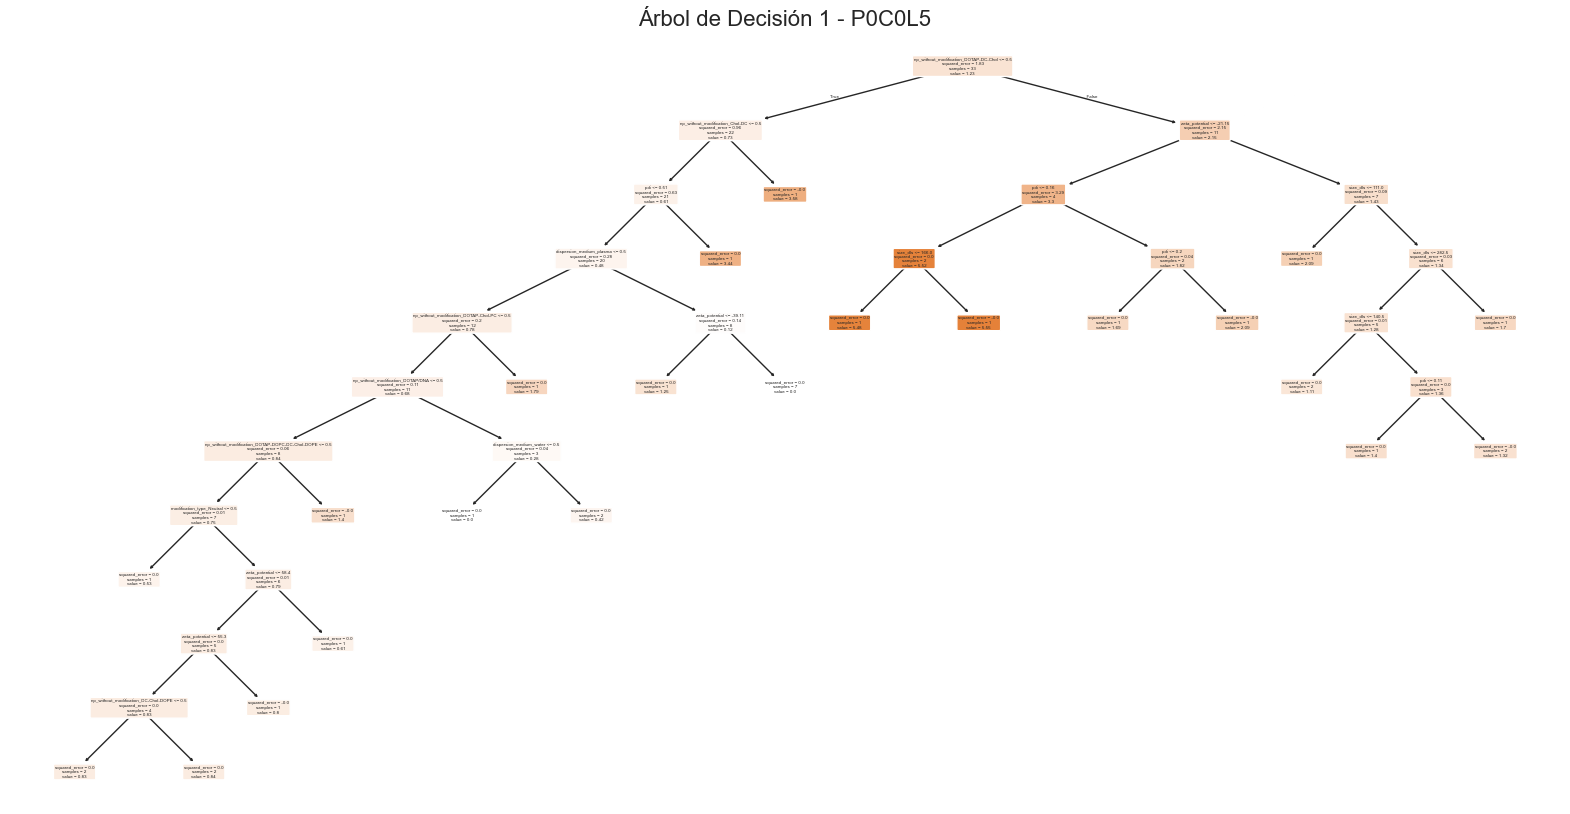


--- Procesando la proteína P0C0L4 ---
✅ Árbol 1 guardado en: ./graficos_pdf\Arbol_1_P0C0L4.pdf


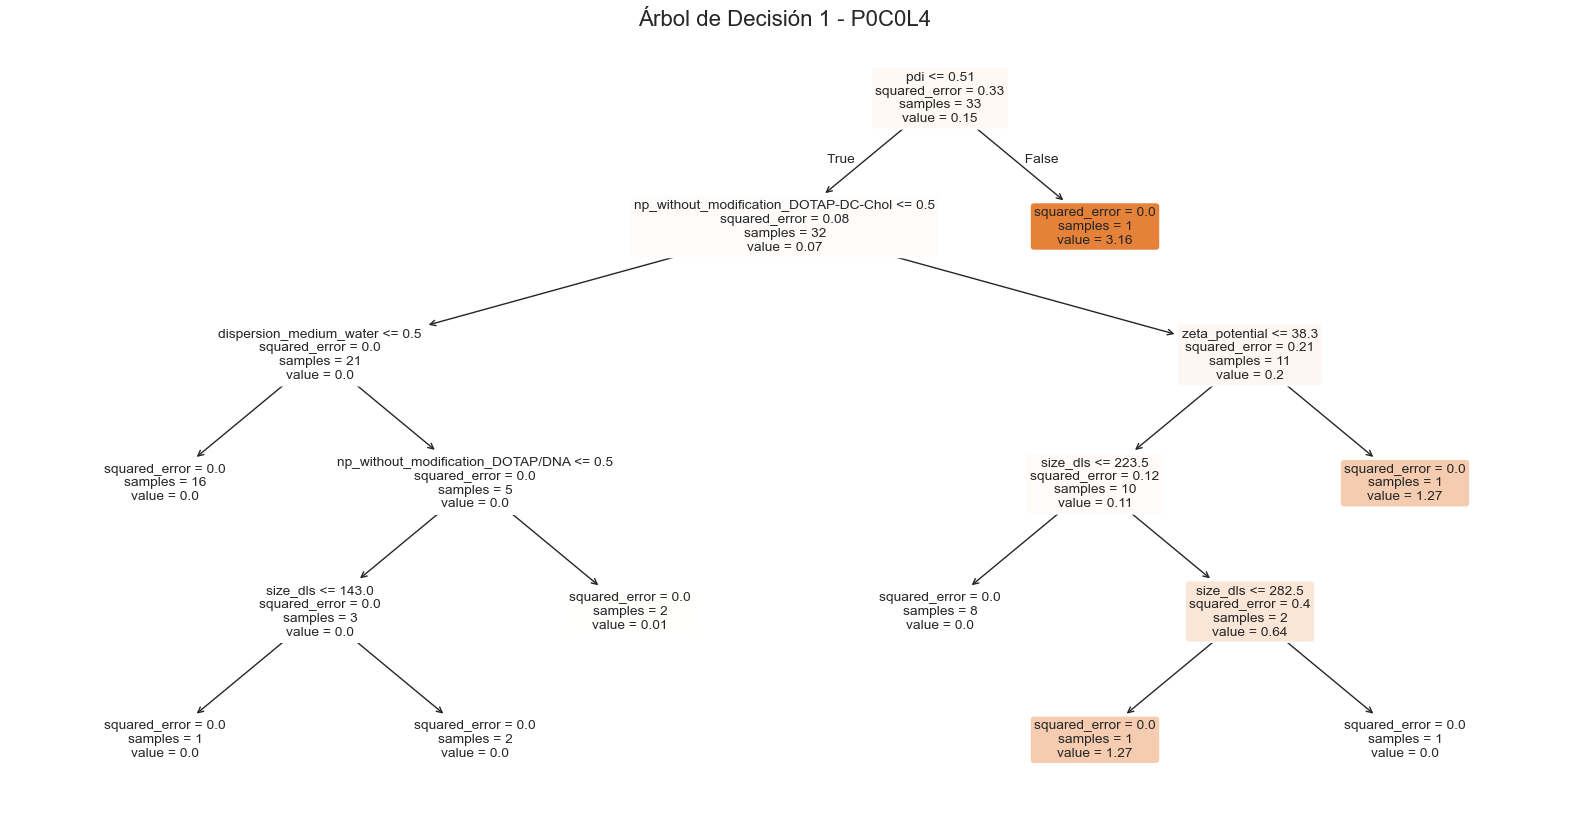

Advertencia: Modelo para P0D0X6 no encontrado. Se omite.

--- Procesando la proteína P02741 ---
✅ Árbol 1 guardado en: ./graficos_pdf\Arbol_1_P02741.pdf


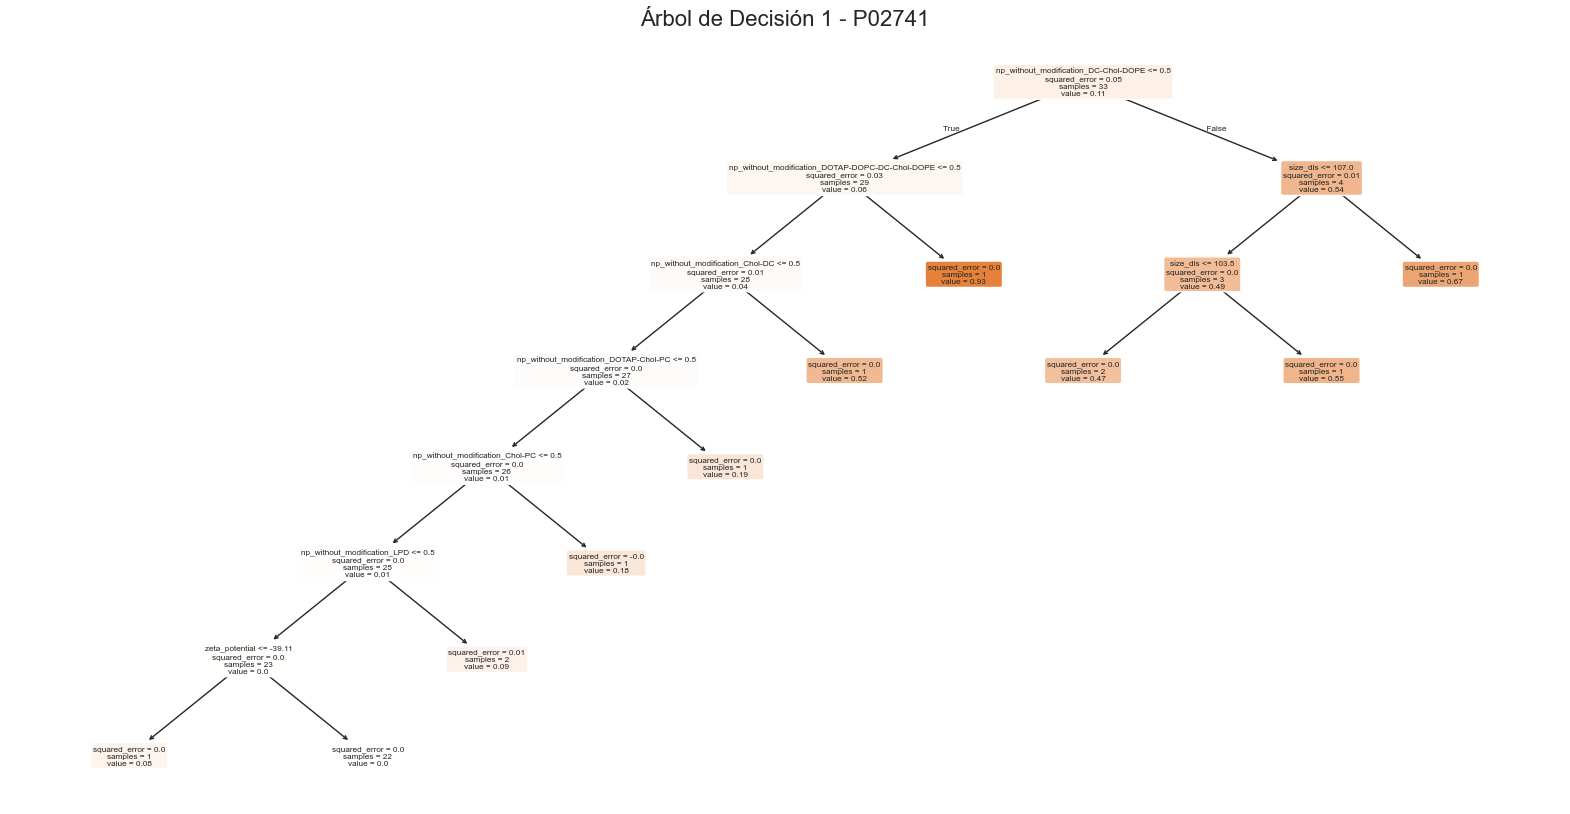


--- Procesando la proteína P11226 ---
✅ Árbol 1 guardado en: ./graficos_pdf\Arbol_1_P11226.pdf


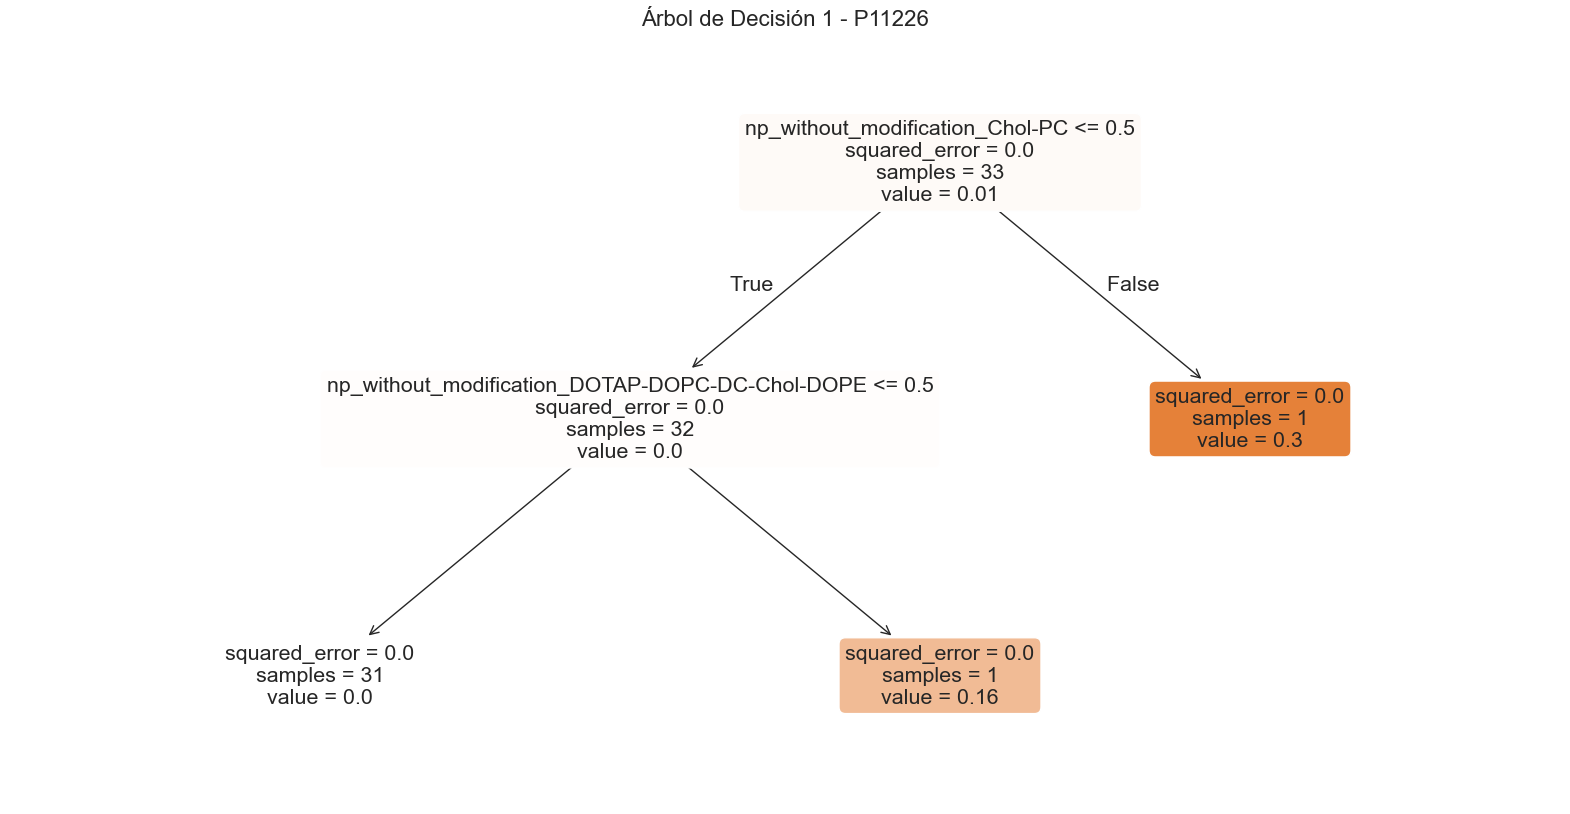

In [16]:
# Lista de proteínas
proteinas_a_visualizar = ["P02768", "P01024", "P0C0L5", "P0C0L4", "P0D0X6", "P02741", "P11226"]

# Ejecutar
visualizar_arboles(proteinas_a_visualizar)